# Q1. Seeds

In [1]:
import sys
sys.path.insert(0, '../src')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import metrics
import models
from data import CONDITIONS, ALL_CONDITIONS

W1117 00:00:20.073000 17909 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


In [2]:
SEEDS = [0, 1, 2]
WAV2VEC_ESC10 = False  # about 1 hour per seed
RUNS = [('sc_small', m) for m in models.MODELS] + [('esc10', m) for m in models.MODELS if m != 'wav2vec' or WAV2VEC_ESC10]

In [3]:
for dataset, model in RUNS:
    for seed in SEEDS:
        print(dataset, model, seed, flush=True)
        models.get_logits(dataset, model, seed)

sc_small rf 0


sc_small rf 1


sc_small rf 2


sc_small cnn 0


    epoch 1/20  val_loss 2.286  2s


    epoch 2/20  val_loss 2.243  2s


... (677 outputs left out)

    epoch 12/15  val_loss 0.397  37s


    epoch 13/15  val_loss 0.390  40s


    epoch 14/15  val_loss 0.352  43s


    epoch 15/15  val_loss 0.370  46s


In [4]:
def over_seeds(dataset, model, condition):
    rows = []
    for seed in SEEDS:
        d = models.get_logits(dataset, model, seed)
        m = metrics.evaluate(d[f'test_{condition}'], d['y_test'], 1.0)
        m['n'] = len(d['y_test'])
        rows.append(m)
    return pd.DataFrame(rows)

clean = []
for dataset, model in RUNS:
    r = over_seeds(dataset, model, 'clean')
    p = r.acc.mean()
    clean.append({'dataset': dataset, 'model': model, 'acc_mean': p, 'acc_std': r.acc.std(), 'ci_95': 1.96 * np.sqrt(p * (1 - p) / r.n[0])})
clean = pd.DataFrame(clean)
clean.round(3)

,dataset,model,acc_mean,acc_std,ci_95
0,sc_small,rf,0.426,0.010,0.015
1,sc_small,cnn,0.607,0.008,0.015
2,sc_small,resnet,0.508,0.036,0.015
3,sc_small,wav2vec,0.665,0.488,0.014
4,esc10,rf,0.789,0.006,0.040
5,esc10,cnn,0.834,0.003,0.036
6,esc10,resnet,0.877,0.005,0.032


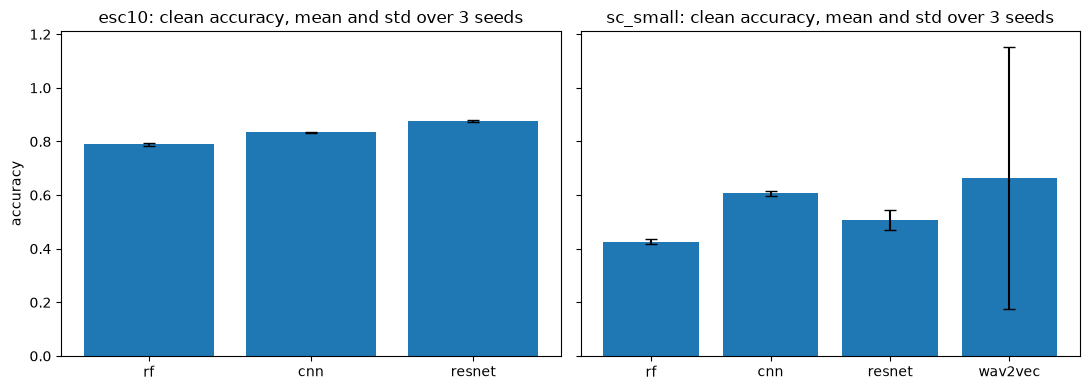

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, dataset in zip(axes, ['esc10', 'sc_small']):
    part = clean[clean.dataset == dataset]
    ax.bar(part.model, part.acc_mean, yerr=part.acc_std, capsize=4)
    ax.set_title(f'{dataset}: clean accuracy, mean and std over {len(SEEDS)} seeds')
axes[0].set_ylabel('accuracy')
plt.tight_layout(); fig.savefig('../results/figures/' + 'q1_seeds_clean' + '.png', dpi=150, bbox_inches='tight'); plt.show()

In [6]:
rows = []
for dataset, model in RUNS:
    for condition in ['white_0', 'real_0']:
        r = over_seeds(dataset, model, condition)
        rows.append({
            'dataset': dataset, 'model': model, 'condition': condition,
            'acc': r.acc.mean(), 'acc_std': r.acc.std(),
            'ece': r.ece.mean(), 'ece_std': r.ece.std(),
            'overconf': r.overconf.mean(), 'overconf_std': r.overconf.std(),
        })
pd.DataFrame(rows).round(3)

,dataset,model,condition,acc,acc_std,ece,ece_std,overconf,overconf_std
0,sc_small,rf,white_0,0.113,0.012,0.128,0.059,0.128,0.058
1,sc_small,rf,real_0,0.138,0.021,0.070,0.045,0.070,0.045
2,sc_small,cnn,white_0,0.161,0.074,0.483,0.374,0.482,0.376
3,sc_small,cnn,real_0,0.154,0.029,0.358,0.180,0.358,0.180
4,sc_small,resnet,white_0,0.114,0.009,0.295,0.055,0.295,0.055
5,sc_small,resnet,real_0,0.135,0.007,0.326,0.066,0.326,0.066
6,sc_small,wav2vec,white_0,0.289,0.163,0.100,0.087,0.097,0.085
7,sc_small,wav2vec,real_0,0.319,0.190,0.108,0.096,0.108,0.096
8,esc10,rf,white_0,0.169,0.004,0.268,0.002,0.268,0.002
9,esc10,rf,real_0,0.234,0.001,0.141,0.004,0.140,0.002
